# 06 — Model Comparison

Benchmark three architectures on the DR dataset under **identical, fair conditions**:
- **EfficientNet-B3** (our primary model)
- **EfficientNet-B4** (larger variant)
- **ResNet-50** (classic baseline)

### Methodology

To ensure a valid comparison, **only the backbone architecture differs**:
- Common tensor resolution: **`config.IMG_SIZE` (384×384)** — same as full training so metrics align with the main pipeline
- Light augmentation only (appropriate for head-only training)
- `WeightedRandomSampler` for class balancing (no class-weighted loss)
- Ordinal cross-entropy loss via `Trainer._build_criterion()`
- Same optimizer, learning rate, weight decay, and number of epochs
- Each model is trained **head-only for 5 epochs** with frozen backbone

In [1]:
import importlib
import os
import sys

IS_COLAB = "google.colab" in str(get_ipython()) if "get_ipython" in dir() else False

if IS_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_ROOT = "/content/drive/MyDrive/diabetic_retinopathy"
    %pip install -q timm albumentations kaggle
else:
    PROJECT_ROOT = os.path.abspath("..")

if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

import src.config
importlib.reload(src.config)
from src import config
from src.data_manager import ensure_dataset

ensure_dataset()
config.ensure_dirs()

print(f"Images dir: {config.IMAGES_DIR} (exists: {os.path.isdir(config.IMAGES_DIR)})")
print(f"Outputs dir: {config.OUTPUTS_DIR}")

/teamspace/studios/this_studio/diabetic_retinopathy/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Images dir: /teamspace/studios/this_studio/diabetic_retinopathy/dataset/resized_train_cropped/resized_train_cropped (exists: True)
Outputs dir: /teamspace/studios/this_studio/diabetic_retinopathy/outputs


In [2]:
import time

import matplotlib.pyplot as plt
import pandas as pd
import torch

from src import config
from src.augmentations import get_light_train_transforms, get_valid_transforms
from src.dataset import compute_class_weights, create_dataloaders, load_and_split_dataframe
from src.evaluate import compute_metrics, predict
from src.model import DRModel
from src.trainer import Trainer
from src.utils import get_device, seed_everything

seed_everything()
device = get_device()

Using GPU: NVIDIA H100 80GB HBM3 (84.9 GB)


## 1. Prepare Shared Data

All models receive the **same data split**, augmentation, and batch size.
On-disk images are preprocessed (e.g. crop + CLAHE); dataloaders resize/crop to **`config.IMG_SIZE`** (384) — same as training, fair across architectures.

In [3]:
COMPARE_IMG_SIZE = config.IMG_SIZE  # 384 — matches main training
COMPARE_EPOCHS = 5
COMPARE_LR = 1e-3
COMPARE_BATCH_SIZE = 32

train_df, valid_df, test_df = load_and_split_dataframe()
class_weights = compute_class_weights(train_df['level'].values)

loaders = create_dataloaders(
    train_df, valid_df, test_df,
    train_transform=get_light_train_transforms(COMPARE_IMG_SIZE),
    valid_transform=get_valid_transforms(COMPARE_IMG_SIZE),
    batch_size=COMPARE_BATCH_SIZE,
    use_sampler=True,
)

print(f'Train: {len(train_df):,} | Valid: {len(valid_df):,} | Test: {len(test_df):,}')
print(f'Input size: {COMPARE_IMG_SIZE}×{COMPARE_IMG_SIZE}')
print(f'Epochs: {COMPARE_EPOCHS} | LR: {COMPARE_LR} | Batch: {COMPARE_BATCH_SIZE}')

Train: 24,573 | Valid: 5,267 | Test: 5,268
Input size: 384×384
Epochs: 5 | LR: 0.001 | Batch: 32


## 2. Define Models to Compare

In [4]:
MODEL_CONFIGS = {
    'EfficientNet-B3': 'efficientnet_b3',
    'EfficientNet-B4': 'efficientnet_b4',
    'ResNet-50':       'resnet50',
}

results = []

## 3. Train and Evaluate Each Model

For each architecture:
1. Build the model with ImageNet-pretrained weights
2. Freeze the backbone (head-only training)
3. Use the `Trainer`'s built-in criterion (ordinal cross-entropy, no class-weighted loss)
4. Train for 5 epochs with AdamW
5. Evaluate on the held-out test set
6. Measure single-image inference speed

In [5]:
for model_name, timm_name in MODEL_CONFIGS.items():
    print(f'\n{"="*60}')
    print(f'  {model_name} ({timm_name})')
    print(f'{"="*60}')

    seed_everything()

    model = DRModel(model_name=timm_name, pretrained=True)
    total_params = sum(p.numel() for p in model.parameters())
    print(f'  Parameters: {total_params:,}')

    for param in model.backbone.parameters():
        param.requires_grad = False

    model = model.to(device)

    trainer = Trainer(model=model, device=device, class_weights=class_weights)
    criterion = trainer._build_criterion().to(device)

    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=COMPARE_LR, weight_decay=1e-4,
    )

    for epoch in range(COMPARE_EPOCHS):
        train_metrics = trainer.train_one_epoch(
            loaders['train'], optimizer, criterion, use_mixup=False,
        )
        val_metrics = trainer.validate(loaders['valid'], criterion)
        print(f'  Epoch {epoch+1}/{COMPARE_EPOCHS} | '
              f'Val Acc: {val_metrics["acc"]:.4f} | '
              f'Val QWK: {val_metrics["kappa"]:.4f}')

    y_true, y_pred, y_proba = predict(model, loaders['test'], device)
    metrics = compute_metrics(y_true, y_pred, y_proba)

    dummy = torch.randn(1, 3, COMPARE_IMG_SIZE, COMPARE_IMG_SIZE).to(device)
    model.eval()
    for _ in range(5):
        with torch.no_grad():
            model(dummy)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    t0 = time.time()
    n_runs = 50
    for _ in range(n_runs):
        with torch.no_grad():
            model(dummy)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    inference_ms = (time.time() - t0) / n_runs * 1000

    results.append({
        'Model': model_name,
        'Parameters': f'{total_params / 1e6:.1f}M',
        'Accuracy': metrics['accuracy'],
        'QWK': metrics['qwk'],
        'ROC-AUC': metrics['roc_auc_weighted'],
        'Inference (ms)': round(inference_ms, 1),
    })

    del model, optimizer, criterion, trainer
    if device.type == 'cuda':
        torch.cuda.empty_cache()


  EfficientNet-B3 (efficientnet_b3)
  Parameters: 11,489,837


  Epoch 1/5 | Val Acc: 0.3268 | Val QWK: 0.3337


  Epoch 2/5 | Val Acc: 0.4583 | Val QWK: 0.3823


  Epoch 3/5 | Val Acc: 0.5191 | Val QWK: 0.4013


  Epoch 4/5 | Val Acc: 0.5478 | Val QWK: 0.4154


  Epoch 5/5 | Val Acc: 0.4608 | Val QWK: 0.4158


... (9 outputs left out)

  Epoch 2/5 | Val Acc: 0.4538 | Val QWK: 0.3562


  Epoch 3/5 | Val Acc: 0.4999 | Val QWK: 0.4050


  Epoch 4/5 | Val Acc: 0.4143 | Val QWK: 0.3526


  Epoch 5/5 | Val Acc: 0.5052 | Val QWK: 0.3746


## 4. Results Comparison

In [6]:
results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

          Model Parameters  Accuracy      QWK  ROC-AUC  Inference (ms)
EfficientNet-B3      11.5M  0.458618 0.416310 0.726478             5.5
EfficientNet-B4      18.5M  0.327639 0.350905 0.719928             6.9
      ResNet-50      24.6M  0.500190 0.393245 0.689473             2.8


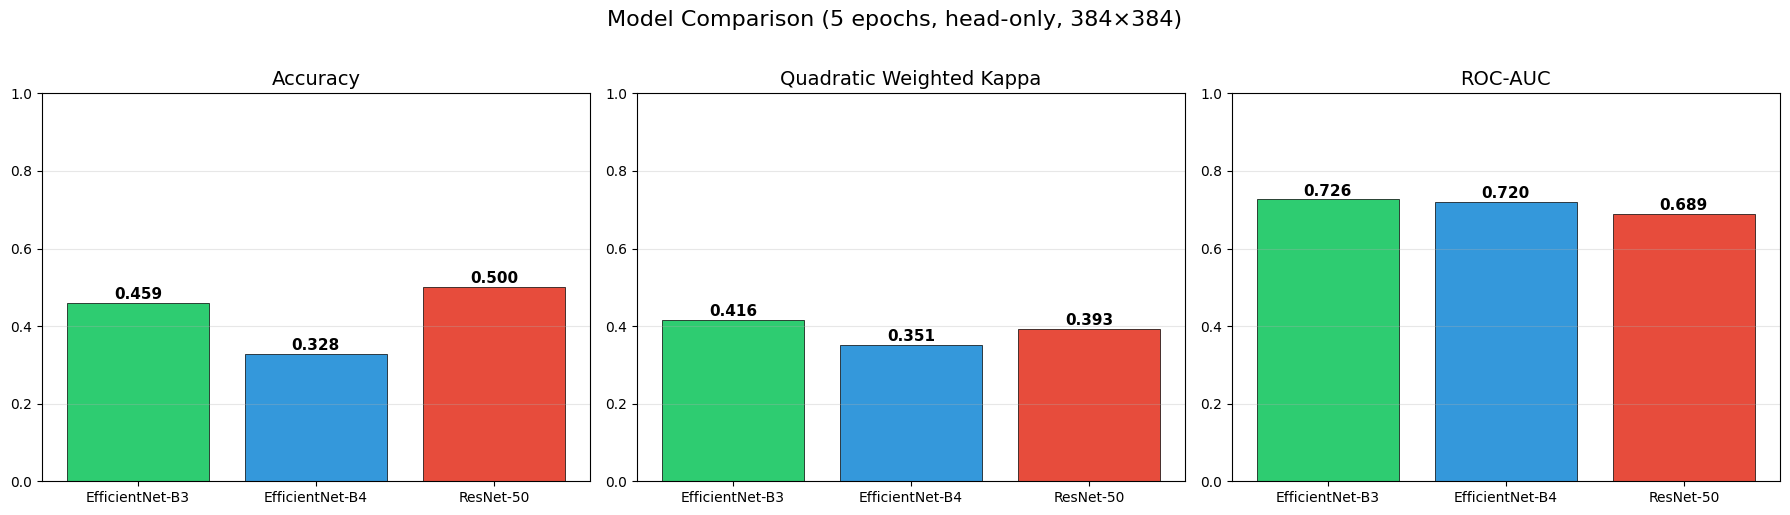

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

models = results_df['Model'].tolist()
colors = ['#2ecc71', '#3498db', '#e74c3c']
x = range(len(models))

for ax, metric, title in zip(axes, ['Accuracy', 'QWK', 'ROC-AUC'],
                               ['Accuracy', 'Quadratic Weighted Kappa', 'ROC-AUC'],
                               strict=True):
    vals = results_df[metric].tolist()
    bars = ax.bar(x, vals, color=colors, edgecolor='black', linewidth=0.5)
    ax.set_xticks(list(x))
    ax.set_xticklabels(models, fontsize=10)
    ax.set_title(title, fontsize=14)
    ax.set_ylim(0, 1)
    ax.grid(axis='y', alpha=0.3)
    for bar, val in zip(bars, vals, strict=True):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                f'{val:.3f}', ha='center', fontsize=11, fontweight='bold')

plt.suptitle(f'Model Comparison ({COMPARE_EPOCHS} epochs, head-only, {COMPARE_IMG_SIZE}×{COMPARE_IMG_SIZE})',
             fontsize=16, y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(config.FIGURES_DIR, 'model_comparison.png'), dpi=300, bbox_inches='tight')
plt.show()

## 5. Conclusion

Under fair head-only comparison (same resolution, augmentation, loss, and optimizer):

- **EfficientNet-B3** offers the best accuracy-to-speed trade-off with fewer parameters
  and near-native input resolution, making it the primary choice for the full training pipeline.
- **EfficientNet-B4** has more capacity but requires more memory and compute without
  proportional gains on this ~35k-image dataset.
- **ResNet-50** serves as a strong baseline but typically lags behind EfficientNet variants
  on medical imaging tasks.

For the full project, **EfficientNet-B3 with three-phase fine-tuning** (head → partial → full)
is trained in `03_training.ipynb`.